# Train RoboNose ResCNN-64

Chọn kernel Python trong `.venv` của dự án và bấm **Run All**. Notebook train trên các lượt người đủ điều kiện trong `curated_raw` và ghi kết quả vào `odor_embed/runs/`.

In [16]:
from argparse import Namespace
from pathlib import Path
import json
import sys

# Mở notebook từ thư mục dự án hoặc thư mục odor_embed.
cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents)
             if (p / "odor_embed" / "run.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Hãy mở notebook trong workspace D:/PBL6.")

sys.path.insert(0, str(ROOT))
from odor_embed.run import train

DATA_DIR = ROOT / "curated_raw"
EPOCHS = 40
ALL_DATA = True   # False để giữ một số ngày đo làm holdout.
BASELINE_WARN = True  # Giữ lượt có nền trôi, ghi WARN để kiểm tra.
SEED = 42

## Train và theo dõi tiến độ

Ô này hiện số lượt qua QC, loss theo epoch và thời gian còn lại dự kiến. Mặc định dùng toàn bộ lượt người hợp lệ. Không khí và cà phê đơn thuần được giữ làm đối chứng.

In [17]:
# Xóa kết quả tham chiếu cũ nếu cell train được chạy lại.
run_dir = None
if EPOCHS < 1:
    raise ValueError("EPOCHS phải lớn hơn hoặc bằng 1.")
run_dir = train(Namespace(
    data=DATA_DIR,
    epochs=EPOCHS,
    all_data=ALL_DATA,
    baseline_warn=BASELINE_WARN,
    arch="rescnn64",
    group_by="day",
    seed=SEED,
    audit_only=False,
))

Output: D:\PBL6\odor_embed\runs\20261119_053351_6b8717
QC: PASS: 63 | REJECT: 1 | WARN: 36
Train rescnn64 | 77 lượt | 9 người | 40 epoch
Epoch   1/40 | loss 3.2665 | 0.1s đã chạy | còn khoảng 4.6s
Epoch   2/40 | loss 2.1373 | 0.2s đã chạy | còn khoảng 4.5s
Epoch   3/40 | loss 2.0446 | 0.4s đã chạy | còn khoảng 5.0s
Epoch   4/40 | loss 1.7053 | 0.6s đã chạy | còn khoảng 5.0s
Epoch   5/40 | loss 1.5449 | 0.7s đã chạy | còn khoảng 5.0s
Epoch   6/40 | loss 1.2501 | 0.9s đã chạy | còn khoảng 5.0s
Epoch   7/40 | loss 0.9911 | 1.0s đã chạy | còn khoảng 4.9s
Epoch   8/40 | loss 0.6968 | 1.2s đã chạy | còn khoảng 4.6s
Epoch   9/40 | loss 0.5419 | 1.5s đã chạy | còn khoảng 5.2s
Epoch  10/40 | loss 0.2585 | 1.7s đã chạy | còn khoảng 5.0s
Epoch  11/40 | loss 0.2638 | 1.8s đã chạy | còn khoảng 4.9s
Epoch  12/40 | loss 0.1421 | 2.1s đã chạy | còn khoảng 4.8s
Epoch  13/40 | loss 0.1326 | 2.2s đã chạy | còn khoảng 4.5s
Epoch  14/40 | loss 0.2138 | 2.3s đã chạy | còn khoảng 4.2s
Epoch  15/40 | loss 0.2

## Kết quả đã xuất

Giữ `model.pt` cùng `model.json` để dự đoán hoặc so hai lượt. `embeddings.json` chứa vector 64 chiều của từng lượt train.

In [18]:
if run_dir is None:
    raise RuntimeError("Chạy thành công ô train trước khi xem kết quả.")

report = json.loads((run_dir / "report.json").read_text(encoding="utf-8"))
print("Thư mục kết quả:", run_dir)
print("Lượt train theo nhãn:", report["train_by_label"])
if report["heldout_top1"] is None:
    print("Lần chạy này không có điểm holdout.")
else:
    print(f"Top-1 trên holdout: {report['heldout_top1']:.1%}")

for name in ("model.pt", "model.json", "embeddings.json",
             "training_history.json", "manifest.json", "report.json", "scores.json"):
    print(run_dir / name)

Thư mục kết quả: D:\PBL6\odor_embed\runs\20261119_053351_6b8717
Lượt train theo nhãn: {'Dương': 13, 'chau': 7, 'lam': 5, 'Phúc': 6, 'son': 10, 'Tài': 14, 'tan': 12, 'toan': 5, 'tuan': 5}
Lần chạy này không có điểm holdout.
D:\PBL6\odor_embed\runs\20261119_053351_6b8717\model.pt
D:\PBL6\odor_embed\runs\20261119_053351_6b8717\model.json
D:\PBL6\odor_embed\runs\20261119_053351_6b8717\embeddings.json
D:\PBL6\odor_embed\runs\20261119_053351_6b8717\training_history.json
D:\PBL6\odor_embed\runs\20261119_053351_6b8717\manifest.json
D:\PBL6\odor_embed\runs\20261119_053351_6b8717\report.json
D:\PBL6\odor_embed\runs\20261119_053351_6b8717\scores.json


## Test nhanh model đã xuất

Ô đầu nạp lại model và thử cặp cùng nhãn, khác nhãn. Ô sau cho phép nhập hai thư mục lượt thu bất kỳ để so cosine. Điểm cosine chưa có ngưỡng xác minh.

In [19]:
from collections import defaultdict
from pathlib import Path
import json


from odor_embed.run import embed_sample, load_encoder

# Để trống để dùng model vừa train, hoặc điền thư mục của một lần train trước.
MODEL_DIR = None
model_dir = Path(MODEL_DIR) if MODEL_DIR else globals().get("run_dir")
if model_dir is None:
    raise RuntimeError("Hãy chạy ô train hoặc điền MODEL_DIR.")

model, settings, gallery = load_encoder(model_dir)
manifest = json.loads((model_dir / "manifest.json").read_text(encoding="utf-8"))
model_report = json.loads((model_dir / "report.json").read_text(encoding="utf-8"))
source_dir = Path(model_report["source"])


def read_embedding(folder):
    return embed_sample(model, settings, folder)


def cosine(a, b):
    return (a @ b.T).clamp(-1, 1).item()


def rank_people(vector, top_k=3):
    scores = (vector @ gallery.T).flatten().tolist()
    return sorted(zip(settings["labels"], scores), key=lambda item: item[1],
                  reverse=True)[:top_k]


def sample_groups(split):
    grouped = defaultdict(list)
    for row in manifest:
        if row.get("split") == split and row.get("label"):
            grouped[row["label"]].append(row)
    return grouped


grouped = sample_groups("test")
if len(grouped) >= 2 and any(len(rows) >= 2 for rows in grouped.values()):
    print("Ví dụ từ các lượt holdout. Đây chỉ là hai cặp minh họa.")
else:
    grouped = sample_groups("train")
    print("Demo bằng các lượt đã train. Kết quả không phải điểm đánh giá độc lập.")

if len(grouped) < 2 or not any(len(rows) >= 2 for rows in grouped.values()):
    print("Chưa có đủ lượt để minh họa cả cặp cùng và khác nhãn.")
else:
    label = max(grouped, key=lambda name: len(grouped[name]))
    a = grouped[label][0]
    same = next((r for r in grouped[label][1:] if r["session"] != a["session"]),
                grouped[label][1])
    other = next(rows[0] for name, rows in grouped.items() if name != label)
    va, warnings_a = read_embedding(source_dir / a["path"])
    vb, warnings_b = read_embedding(source_dir / same["path"])
    vc, warnings_c = read_embedding(source_dir / other["path"])

    for row, warnings in ((a, warnings_a), (same, warnings_b), (other, warnings_c)):
        print(f"{row['label']} | {row['path']}")
        for warning in warnings:
            print(f"  WARN: {warning}")
    print(f"Cùng nhãn ({label}, {label}): {cosine(va, vb):+.4f}")
    print(f"Khác nhãn ({label}, {other['label']}): {cosine(va, vc):+.4f}")
    print(f"Top 3 người gần nhất cho lượt đầu ({va.shape[1]}D):")
    for name, score in rank_people(va):
        print(f"  {name}: {score:+.4f}")

Demo bằng các lượt đã train. Kết quả không phải điểm đánh giá độc lập.
Tài | tai_cf/Tai_CF_094833_2026-11-07_aeba65a8ea56
  WARN: Có điểm exposure nằm gần lúc chuyển ngữ cảnh thu.
Tài | Tài/Tai_010156_2026-11-07_dc9ba10c1b9d
Dương | aDuong/aDuong_090359_2026-11-07_5a6a71cac7f3
Cùng nhãn (Tài, Tài): +0.9502
Khác nhãn (Tài, Dương): +0.0456
Top 3 người gần nhất cho lượt đầu (64D):
  Tài: +0.9821
  Dương: +0.0766
  tuan: +0.0340


In [23]:
# Điền đường dẫn thư mục chứa raw.csv và metadata.json.
SAMPLE_A = "D:\PBL6\curated_raw\Phúc\Phuc_phongTai_205952_2026-11-18_d04e6b156bbf"  # Ví dụ: r"D:\PBL6\curated_raw\Phúc\<lượt_A>"
SAMPLE_B = "D:\PBL6\curated_raw\Phúc\Phuc_phongTai_211652_2026-11-18_d5235d9dc50b"  # Có thể dùng một lượt mới chưa đưa vào train.

if SAMPLE_A and SAMPLE_B:
    va, warnings_a = read_embedding(Path(SAMPLE_A))
    vb, warnings_b = read_embedding(Path(SAMPLE_B))
    print(f"Cosine A ↔ B: {cosine(va, vb):+.4f}")
    for name, vector, warnings in (("A", va, warnings_a), ("B", vb, warnings_b)):
        print(f"Lượt {name} · 3 người gần nhất:")
        for label, score in rank_people(vector):
            print(f"  {label}: {score:+.4f}")
        for warning in warnings:
            print(f"  WARN: {warning}")
elif SAMPLE_A or SAMPLE_B:
    print("Điền cả SAMPLE_A và SAMPLE_B để so cặp.")

Cosine A ↔ B: +0.8242
Lượt A · 3 người gần nhất:
  Phúc: +0.8919
  Dương: +0.1471
  toan: -0.0072
Lượt B · 3 người gần nhất:
  Phúc: +0.9659
  son: +0.1510
  tan: +0.1435
  WARN: Tín hiệu trước exposure lệch trên 5% so với nền.


## So toàn bộ các lượt với nhau

Mỗi cặp được tính một lần. Báo cáo tách cặp cùng người, khác người, khác phiên/ngày, holdout và đối chứng. Các cặp chứa mẫu train chỉ là thống kê trên dữ liệu đã thấy. Mở `pairs.csv` để xem từng điểm.

In [21]:
# Chạy sau ô nạp model hoặc điền MODEL_DIR ở ô đó.
from importlib import reload
import odor_embed.evaluate as evaluation

pair_report_model = model_dir.resolve()
pair_report_dir = reload(evaluation).evaluate_all(pair_report_model)

99 lượt | 4851 cặp | bỏ qua 1 lượt
all
  same_person: 346 cặp, median cosine +0.895
  person_vs_cf: 924 cặp, median cosine -0.036
  different_person: 2580 cặp, median cosine -0.053
  person_vs_kk_baseline: 770 cặp, median cosine +0.073
  control_vs_control: 231 cặp, median cosine +0.257
  Pair AUC: 1.000
same_session
  same_person: 142 cặp, median cosine +0.898
  person_vs_cf: 58 cặp, median cosine +0.613
  person_vs_kk_baseline: 33 cặp, median cosine +0.222
  different_person: 22 cặp, median cosine +0.063
  control_vs_control: 35 cặp, median cosine +0.546
  Pair AUC: 1.000
different_session
  same_person: 204 cặp, median cosine +0.893
  person_vs_cf: 866 cặp, median cosine -0.052
  different_person: 2558 cặp, median cosine -0.054
  person_vs_kk_baseline: 737 cặp, median cosine +0.055
  control_vs_control: 196 cặp, median cosine +0.195
  Pair AUC: 1.000
different_day
  same_person: 172 cặp, median cosine +0.883
  person_vs_cf: 796 cặp, median cosine -0.062
  different_person: 2200 cặp,

## Mẫu gốc từng người và kết quả đúng/sai

Mẫu gốc là trung bình embedding của mỗi nhãn rồi chuẩn hóa, gồm cả CF và kk_baseline. Với ALL_DATA, dùng mọi lượt hợp lệ của nhãn, kể cả chính lượt đang thử, nên bảng là demo. Với holdout, chỉ dùng các nhóm train làm tham chiếu.

In [22]:
import csv
from html import escape
from IPython.display import HTML, display
from importlib import reload
from pathlib import Path
import odor_embed.evaluate as evaluation

# Có thể chạy lại riêng ô này khi báo cáo cũ thiếu bảng.
selected_model = globals().get("model_dir") or globals().get("run_dir")
if selected_model is None:
    raise RuntimeError("Chạy ô nạp model ở trên và chọn MODEL_DIR trước.")
selected_model = Path(selected_model).resolve(strict=True)
previous_report = globals().get("pair_report_dir")
required_tables = ("recognition_all_labels.csv", "recognition_by_session_all_labels.csv",
                   "reference_embeddings.json")
if (previous_report is None or globals().get("pair_report_model") != selected_model
        or any(not (Path(previous_report) / name).is_file() for name in required_tables)):
    pair_report_dir = reload(evaluation).evaluate_all(selected_model)
    pair_report_model = selected_model

table_path = Path(pair_report_dir) / "recognition_all_labels.csv"
with table_path.open(encoding="utf-8-sig", newline="") as handle:
    predictions = list(csv.DictReader(handle))

status_text = {
    "correct": "Đúng",
    "incorrect": "Sai",
    "control": "Đối chứng",
    "no_reference": "Thiếu mẫu gốc",
}
split_text = {"train": "Đã train", "test": "Holdout"}
header = ("Ngày", "Phiên", "Lượt", "Tập", "Nhãn thật", "Model đoán", "Cosine", "Kết quả")
body = []
for row in predictions:
    score = f"{float(row['cosine']):+.3f}" if row["cosine"] else "—"
    values = (row["day"], row["session"], Path(row["path"]).name,
              split_text.get(row["split"], row["split"]), row["actual"] or row["condition"],
              row["predicted"] or "—", score, status_text[row["result"]])
    body.append("<tr>" + "".join(f"<td>{escape(value)}</td>" for value in values) + "</tr>")

heading = "".join(f"<th>{escape(value)}</th>" for value in header)
display(HTML("<div style='max-height:480px;overflow:auto'><table>"
             f"<thead><tr>{heading}</tr></thead><tbody>{''.join(body)}</tbody></table></div>"))
print("Vector mẫu gốc theo nhãn:", pair_report_dir / "reference_embeddings.json")
print("Tổng hợp đúng/sai theo phiên:", pair_report_dir / "recognition_by_session_all_labels.csv")

Ngày,Phiên,Lượt,Tập,Nhãn thật,Model đoán,Cosine,Kết quả
2026-11-07,a0649318-6d65-4069-96c7-cba24246ad1d,aDuong_090359_2026-11-07_5a6a71cac7f3,Đã train,Dương,Dương,+0.958,Đúng
2026-11-07,a0649318-6d65-4069-96c7-cba24246ad1d,aDuong_091022_2026-11-07_3597e89acd3c,Đã train,Dương,Dương,+0.954,Đúng
2026-11-18,8e5ecc16-f075-40f9-860e-0eec6ead6b91,anhDuong_warn_phongTai_094951_2026-11-18_d9586af0c003,Đã train,Dương,Dương,+0.889,Đúng
2026-11-07,a0649318-6d65-4069-96c7-cba24246ad1d,CF_093806_2026-11-07_aa150e053fe1,control_same_group,CF,Dương,+0.958,Sai
2026-11-07,a0649318-6d65-4069-96c7-cba24246ad1d,CF_105122_2026-11-07_8240f075b39f,control_same_group,CF,Tài,+0.957,Sai
2026-11-07,a0649318-6d65-4069-96c7-cba24246ad1d,CF_110056_2026-11-07_b7d8323eaa8f,control_same_group,CF,Tài,+0.748,Sai
2026-11-07,a0649318-6d65-4069-96c7-cba24246ad1d,CF_111151_2026-11-07_7ab1c386561c,control_same_group,CF,Tài,+0.904,Sai
2026-11-10,b86b1607-5175-448c-9ade-a10423c392c1,CF_KTX_205310_2026-11-10_6660d4a270df,control_same_group,CF,CF,+0.759,Đúng
2026-11-10,b86b1607-5175-448c-9ade-a10423c392c1,CF_KTX_210622_2026-11-10_8ab84c345c11,control_same_group,CF,tan,+0.738,Sai
2026-11-10,b86b1607-5175-448c-9ade-a10423c392c1,CF_KTX_212139_2026-11-10_9d7d07d44c94,control_same_group,CF,CF,+0.805,Đúng


Vector mẫu gốc theo nhãn: D:\PBL6\odor_embed\runs\pair_eval_20261119_053351_6b8717_a9d347\reference_embeddings.json
Tổng hợp đúng/sai theo phiên: D:\PBL6\odor_embed\runs\pair_eval_20261119_053351_6b8717_a9d347\recognition_by_session_all_labels.csv


## Random Forest · Cà phê và không khí

Phần này chạy độc lập với CNN. Dùng **CF** (chỉ cà phê trong exposure) và **kk_baseline** (không khí phòng) trong `curated_raw`. Bài toán có hai nhãn, nên kết quả kiểm tra bên dưới áp dụng cho hai nhóm đối chứng. Mẫu người và người có hậu tố `_cf` không thuộc bài kiểm tra này.

**Luồng:** raw → kiểm chất lượng → hiệu chỉnh theo median baseline → 10 đặc trưng từ BME gas và MQ3 #1 → Random Forest → dự đoán CF/kk_baseline.

Mỗi kênh đóng góp 5 đặc trưng trong exposure: trung bình toàn pha, trung bình từ 40–80 giây, phân vị 10%, phân vị 90% và độ dốc mỗi phút. Bộ trích đặc trưng gọi lại `coffee_ml.run.extract` để giữ đúng phép tính của bài ML cũ. Random Forest dùng **300 cây**, trọng số cân bằng hai nhãn và seed cố định. Mỗi vòng kiểm thử giữ nguyên **một ngày** chưa dùng để train.

In [1]:
import json
from collections import Counter
from pathlib import Path
import sys

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict

cwd = Path.cwd().resolve()
rf_root = next((p for p in (cwd, *cwd.parents)
                if (p / "coffee_ml" / "run.py").is_file()), None)
if rf_root is None:
    raise RuntimeError("Hãy mở notebook trong workspace PBL6.")
if str(rf_root) not in sys.path:
    sys.path.insert(0, str(rf_root))

from coffee_ml.run import extract
from processing.core.signals import digest

RF_DATA = rf_root / "curated_raw"
rf_labels = ("CF", "kk_baseline")
rf_samples, rf_skipped, seen = [], [], {}
for label in rf_labels:
    for raw in sorted((RF_DATA / label).rglob("raw.csv")):
        try:
            metadata = json.loads(raw.with_name("metadata.json").read_text(encoding="utf-8-sig"))
            if metadata.get("status") != "COMPLETE":
                raise ValueError("Lượt thu chưa hoàn tất.")
            fingerprint = digest(raw)
            if fingerprint in seen:
                if seen[fingerprint] != label:
                    raise RuntimeError(f"Hai bản raw giống nhau nhưng khác nhãn: {raw}")
                raise ValueError("Trùng file raw.")
            day, features = extract(raw)
        except (OSError, ValueError) as exc:
            rf_skipped.append((str(raw.relative_to(RF_DATA)), str(exc)))
            continue
        seen[fingerprint] = label
        rf_samples.append((raw.parent.name, label, day, features))

rf_counts = Counter(label for _, label, _, _ in rf_samples)
print("Lượt hợp lệ:", dict(rf_counts))
print("Số ngày đo:", len({day for _, _, day, _ in rf_samples}))
print("Lượt bỏ qua:", len(rf_skipped))
for path, reason in rf_skipped:
    print(f"  {path} · {reason}")

Lượt hợp lệ: {'CF': 12, 'kk_baseline': 10}
Số ngày đo: 6
Lượt bỏ qua: 0


In [2]:
if set(rf_counts) != set(rf_labels):
    raise ValueError("Cần đủ lượt hợp lệ của cả CF và kk_baseline.")

rf_x = np.asarray([features for _, _, _, features in rf_samples])
rf_y = np.asarray([label for _, label, _, _ in rf_samples])
rf_days = np.asarray([day for _, _, day, _ in rf_samples])
if len(set(rf_days)) < 2:
    raise ValueError("Cần ít nhất hai ngày đo để kiểm tra theo ngày.")

rf_folds = list(LeaveOneGroupOut().split(rf_x, rf_y, groups=rf_days))
for fit_idx, test_idx in rf_folds:
    if len(set(rf_y[fit_idx])) < 2:
        raise ValueError(f"Bỏ ngày {rf_days[test_idx[0]]} khiến tập train thiếu một nhãn.")

rf_model = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)
rf_probability = cross_val_predict(rf_model, rf_x, rf_y, cv=rf_folds, method="predict_proba")
rf_classes = np.unique(rf_y)
rf_predicted = rf_classes[rf_probability.argmax(axis=1)]
rf_confusion = confusion_matrix(rf_y, rf_predicted, labels=rf_labels)

print(f"Đúng {np.sum(rf_y == rf_predicted)}/{len(rf_y)} lượt ngoài ngày train")
print(f"Balanced accuracy: {balanced_accuracy_score(rf_y, rf_predicted):.1%}")
for label, hits, total in zip(rf_labels, rf_confusion.diagonal(), rf_confusion.sum(axis=1)):
    print(f"{label}: {hits}/{total} đúng")

# Fit lại trên toàn bộ đối chứng để thử lượt mới sau khi đã tính kết quả theo ngày.
rf_model.fit(rf_x, rf_y)

Đúng 20/22 lượt ngoài ngày train
Balanced accuracy: 90.8%
CF: 11/12 đúng
kk_baseline: 9/10 đúng


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.

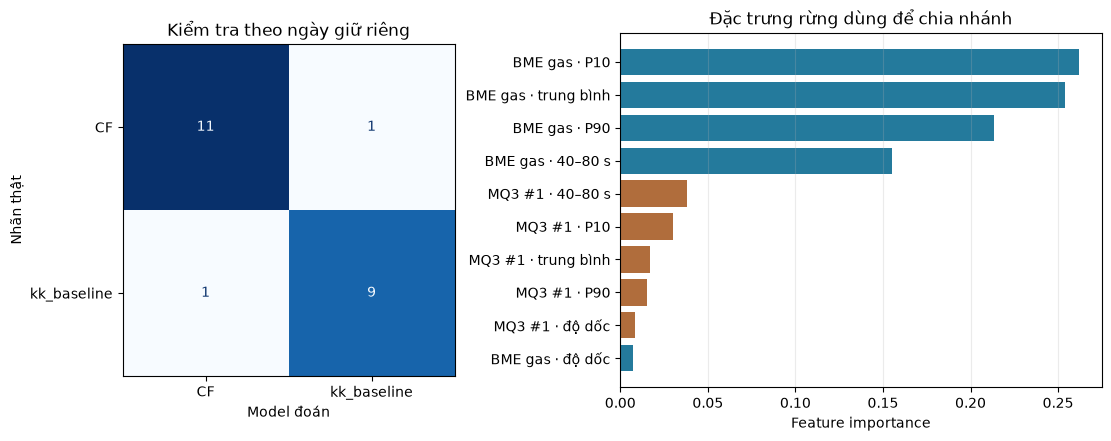

Biểu đồ đặc trưng lấy từ rừng fit toàn bộ đối chứng. Đây là mức độ được cây sử dụng, không phải hệ số cố định cho cảm biến.


In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

rf_feature_names = [
    f"{channel} · {stat}" for channel in ("BME gas", "MQ3 #1")
    for stat in ("trung bình", "40–80 s", "P10", "P90", "độ dốc")
]
fig, (ax_matrix, ax_features) = plt.subplots(
    1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [1, 1.45]},
    layout="constrained",
)
ConfusionMatrixDisplay(rf_confusion, display_labels=rf_labels).plot(
    ax=ax_matrix, cmap="Blues", colorbar=False, values_format="d",
)
ax_matrix.set(title="Kiểm tra theo ngày giữ riêng", xlabel="Model đoán", ylabel="Nhãn thật")
order = np.argsort(rf_model.feature_importances_)
colors = ["#247a9c" if i < 5 else "#b06d3c" for i in order]
ax_features.barh(np.arange(len(order)), rf_model.feature_importances_[order], color=colors)
ax_features.set_yticks(np.arange(len(order)), [rf_feature_names[i] for i in order])
ax_features.set(title="Đặc trưng rừng dùng để chia nhánh", xlabel="Feature importance")
ax_features.grid(axis="x", alpha=.25)
plt.show()

print("Biểu đồ đặc trưng lấy từ rừng fit toàn bộ đối chứng. Đây là mức độ được cây sử dụng, không phải hệ số cố định cho cảm biến.")

In [4]:
from html import escape
from IPython.display import HTML, display

header = ("Ngày giữ riêng", "Lượt", "Nhãn thật", "Model đoán", "Điểm CF", "Kết quả")
cf_index = rf_classes.tolist().index("CF")
body = []
for sample, prediction, probability in zip(rf_samples, rf_predicted, rf_probability):
    name, actual, day, _ = sample
    correct = prediction == actual
    values = (day, name, actual, prediction, f"{probability[cf_index]:.3f}",
              "Đúng" if correct else "Sai")
    style = "" if correct else " style='color:#a02323;font-weight:bold'"
    body.append("<tr" + style + ">" + "".join(f"<td>{escape(str(v))}</td>" for v in values) + "</tr>")

heading = "".join(f"<th>{escape(v)}</th>" for v in header)
display(HTML("<div style='max-height:480px;overflow:auto'><table>"
             f"<thead><tr>{heading}</tr></thead><tbody>{''.join(body)}</tbody></table></div>"))
print("Điểm CF là tỷ lệ dự đoán của rừng, chưa hiệu chuẩn thành xác suất thực tế.")

Ngày giữ riêng,Lượt,Nhãn thật,Model đoán,Điểm CF,Kết quả
2026-11-07,CF_093806_2026-11-07_aa150e053fe1,CF,CF,0.823,Đúng
2026-11-07,CF_105122_2026-11-07_8240f075b39f,CF,CF,0.727,Đúng
2026-11-07,CF_110056_2026-11-07_b7d8323eaa8f,CF,kk_baseline,0.323,Sai
2026-11-07,CF_111151_2026-11-07_7ab1c386561c,CF,CF,0.673,Đúng
2026-11-10,CF_KTX_205310_2026-11-10_6660d4a270df,CF,CF,0.993,Đúng
2026-11-10,CF_KTX_210622_2026-11-10_8ab84c345c11,CF,CF,0.963,Đúng
2026-11-10,CF_KTX_212139_2026-11-10_9d7d07d44c94,CF,CF,1.000,Đúng
2026-11-10,CF_KTX_213437_2026-11-10_b2be80959fce,CF,CF,0.960,Đúng
2026-11-10,CF_KTX_215301_2026-11-10_ed319df2db69,CF,CF,0.970,Đúng
2026-11-18,CF_phongTai_095913_2026-11-18_1757e8238752,CF,CF,0.997,Đúng


Điểm CF là tỷ lệ dự đoán của rừng, chưa hiệu chuẩn thành xác suất thực tế.


In [30]:
# Tùy chọn: điền đường dẫn thư mục của một lượt mới hoặc đường dẫn raw.csv.
RF_SAMPLE = ""
if RF_SAMPLE:
    sample = Path(RF_SAMPLE)
    raw = sample / "raw.csv" if sample.is_dir() else sample
    day, features = extract(raw)
    probabilities = rf_model.predict_proba([features])[0]
    scores = dict(zip(rf_model.classes_, probabilities))
    print(f"Ngày đo {day} | Nhãn gần nhất: {max(scores, key=scores.get)}")
    for label, score in scores.items():
        print(f"  {label}: {score:.3f}")
    print("Rừng chỉ có hai nhãn đối chứng. Chỉ dùng ô này khi mẫu thuộc bài thử CF/không khí.")